# Funnels and Markov chains: transition counts

A user session is a path through states: landing → product → cart → checkout → purchase, with
detours, loops and exits. Model it as a first-order Markov chain with transition matrix $P$. The
likelihood of a set of observed paths is

$$\prod_{\text{paths}}\prod_{t} P_{s_{t-1}, s_t} = \prod_{i,j} P_{ij}^{N_{ij}},$$

so the matrix of transition counts $N_{ij}$ is sufficient, however many sessions and however long
they ran. Each row is then a multinomial: $N_{i\cdot} \sim \text{Multinomial}(n_i, P_{i\cdot})$, and a
Dirichlet prior per row is conjugate.

A *funnel* is the special case where the only moves are "advance one stage" or "leave". The row
multinomials become binomials: $n_{k+1} \sim \text{Binomial}(n_k, p_k)$, and the sufficient statistic
is the head-count reaching each stage. That is exactly what product dashboards already report,
so this is a case where the compressed data is often the *only* data you get.

In [1]:
import time
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(404)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)


def timed_fit(model, label, n_rows, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    return idata, {"model": label, "rows in likelihood": n_rows, "wall time (s)": round(secs, 1),
                   "min ESS/s": round(ess / secs, 1)}

## Part 1: sessions as a Markov chain

Four transient states and two absorbing ones, and two traffic sources with different behaviour.
We simulate 20,000 sessions and keep every individual transition.

In [2]:
STATES = ["landing", "product", "cart", "checkout", "purchase", "exit"]
TRANSIENT, ABSORB = 4, 2
P_true = np.array([
    # paid traffic
    [[0.00, 0.55, 0.00, 0.00, 0.00, 0.45],
     [0.20, 0.35, 0.18, 0.00, 0.00, 0.27],
     [0.00, 0.30, 0.05, 0.45, 0.00, 0.20],
     [0.00, 0.00, 0.15, 0.00, 0.60, 0.25]],
    # organic traffic
    [[0.00, 0.65, 0.00, 0.00, 0.00, 0.35],
     [0.15, 0.40, 0.20, 0.00, 0.00, 0.25],
     [0.00, 0.25, 0.05, 0.50, 0.00, 0.20],
     [0.00, 0.00, 0.10, 0.00, 0.70, 0.20]],
])
n_sess = 20_000
source = rng.integers(0, 2, n_sess)

src, frm, to = [], [], []
state = np.zeros(n_sess, int)
active = np.ones(n_sess, bool)
while active.any():
    idx = np.flatnonzero(active)
    probs = P_true[source[idx], state[idx]]
    nxt = (probs.cumsum(1) > rng.random(len(idx))[:, None]).argmax(1)
    src.append(source[idx]); frm.append(state[idx]); to.append(nxt)
    state[idx] = nxt
    active[idx] = nxt < TRANSIENT
transitions = pd.DataFrame({"source": np.concatenate(src), "from": np.concatenate(frm), "to": np.concatenate(to)})

# the sufficient statistic: a (source, from, to) count tensor
N = np.zeros((2, TRANSIENT, len(STATES)), int)
np.add.at(N, (transitions.source, transitions["from"], transitions.to), 1)
print(f"{n_sess:,} sessions -> {len(transitions):,} transitions -> {N.size} counts")
pd.DataFrame(N[0], index=STATES[:TRANSIENT], columns=STATES)

20,000 sessions -> 58,669 transitions -> 48 counts


,landing,product,cart,checkout,purchase,exit
landing,0,6658,0,0,0,5551
product,2261,3934,2041,0,0,3008
cart,0,652,119,1074,0,488
checkout,0,0,173,0,633,268


The quantity we actually care about is not any single transition but the probability that a
session starting on the landing page ends in a purchase. For an absorbing chain with transient block
$Q$ and absorbing block $R$, the absorption probabilities are $B = (I-Q)^{-1}R$. We compute it as a
deterministic of the posterior transition matrix, so it inherits the full uncertainty.

In [3]:
coords = {"source": ["paid", "organic"], "from": STATES[:TRANSIENT], "to": STATES}


def transition_prior():
    P = pm.Dirichlet("P", a=np.ones((2, TRANSIENT, len(STATES))), dims=("source", "from", "to"))
    B = [pt.linalg.solve(pt.eye(TRANSIENT) - P[s, :, :TRANSIENT], P[s, :, TRANSIENT:]) for s in range(2)]
    pm.Deterministic("p_purchase", pt.stack([b[0, 0] for b in B]), dims="source")
    return P


# Raw-row likelihood: each transition contributes log P[source, from, to]. (Passing the full
# 6-way row P[source, from] to pm.Categorical per transition is the same likelihood but ~6x slower,
# because it materialises a (transitions x states) probability array at every gradient step.)
with pm.Model(coords=coords) as mc_full:
    P = transition_prior()
    pm.Potential("transitions_loglik", pm.math.log(
        P[transitions.source.values, transitions["from"].values, transitions.to.values]).sum())

with pm.Model(coords=coords) as mc_suff:
    P = transition_prior()
    pm.Multinomial("N", n=N.sum(-1), p=P, observed=N)

idata_mf, rec_mf = timed_fit(mc_full, "Markov: log P per transition", len(transitions))
idata_ms, rec_ms = timed_fit(mc_suff, "Markov: Multinomial on N_ij", N.shape[0] * N.shape[1])

NUTS[nutpie]: [P]
NUTS[nutpie]: [P]


## Part 2: a cohort funnel

12 weekly sign-up cohorts pass through visit → sign-up → activate → pay. Step conversion rates
drift across cohorts, so we pool them hierarchically on the logit scale. The raw data is one
Bernoulli per user per stage they reached; the compressed data is a $12 \times 4$ table of head-counts.

In [4]:
n_coh, steps = 12, ["sign-up", "activate", "pay"]
mu_true, sd_true = np.array([-1.2, 0.3, -1.0]), np.array([0.15, 0.25, 0.20])
logit_p = mu_true[:, None] + sd_true[:, None] * rng.normal(size=(3, n_coh))
p_true = 1 / (1 + np.exp(-logit_p))
visits = rng.integers(1_500, 3_500, n_coh)

# user-level simulation: each user who reaches stage k flips a coin to reach k+1
rows = []
reached = [np.repeat(np.arange(n_coh), visits)]
for k in range(3):
    coh = reached[-1]
    y = rng.binomial(1, p_true[k, coh])
    rows.append(pd.DataFrame({"cohort": coh, "step": k, "y": y}))
    reached.append(coh[y == 1])
users = pd.concat(rows, ignore_index=True)

heads = np.array([np.bincount(r, minlength=n_coh) for r in reached])   # (stage, cohort) head-counts
print(f"{visits.sum():,} visitors -> {len(users):,} user-step rows -> {heads.size} head-counts")
pd.DataFrame(heads[:, :6], index=["visit"] + steps, columns=[f"wk{c}" for c in range(6)])

29,704 visitors -> 40,304 user-step rows -> 48 head-counts


,wk0,wk1,wk2,wk3,wk4,wk5
visit,2037,3184,3230,1911,2017,2254
sign-up,451,661,760,403,455,497
activate,293,320,435,226,254,347
pay,88,55,117,65,71,97


In [5]:
fcoords = {"step": steps, "cohort": np.arange(n_coh)}


def funnel_prior():
    mu = pm.Normal("mu", 0, 1.5, dims="step")
    sd = pm.HalfNormal("sd", 0.5, dims="step")
    z = pm.Normal("z", 0, 1, dims=("step", "cohort"))
    return pm.Deterministic("p", pm.math.invlogit(mu[:, None] + sd[:, None] * z), dims=("step", "cohort"))


with pm.Model(coords=fcoords) as fun_full:
    p = funnel_prior()
    pm.Bernoulli("y", p=p[users.step.values, users.cohort.values], observed=users.y.values)

with pm.Model(coords=fcoords) as fun_suff:
    p = funnel_prior()
    pm.Binomial("n_next", n=heads[:-1], p=p, observed=heads[1:])

idata_ff, rec_ff = timed_fit(fun_full, "Funnel: Bernoulli per user-step", len(users))
idata_fs, rec_fs = timed_fit(fun_suff, "Funnel: Binomial on head-counts", heads[:-1].size)

NUTS[nutpie]: [mu, sd, z]
NUTS[nutpie]: [mu, sd, z]


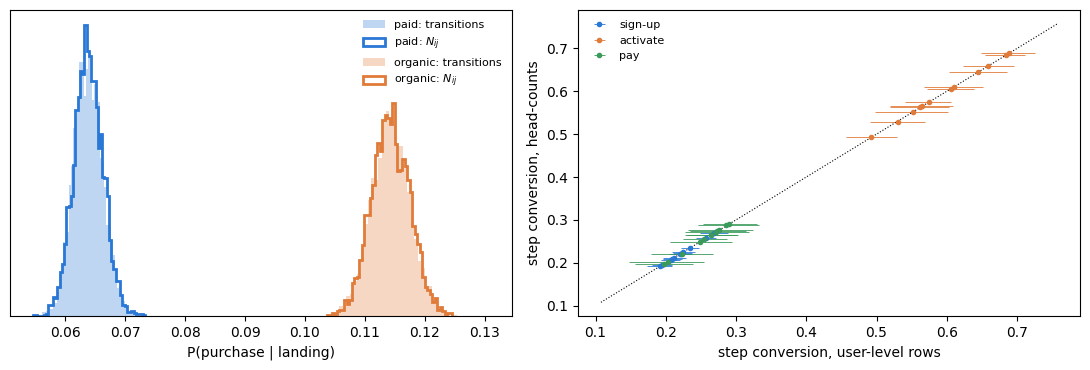

In [6]:
#| label: fig-funnel-equiv
#| fig-cap: "Left: posterior probability that a landing-page session ends in purchase, by traffic source, from every transition (filled) and from the transition-count matrix (line). Right: per-cohort step conversion posterior means and 94% intervals, user rows vs head-counts; points on the diagonal mean the same answer."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for s, col in zip(["paid", "organic"], ["#2a78d6", "#e07b39"]):
    ax.hist(idata_mf.posterior["p_purchase"].sel(source=s).values.ravel(), bins=50, density=True,
            alpha=0.3, color=col, label=f"{s}: transitions")
    ax.hist(idata_ms.posterior["p_purchase"].sel(source=s).values.ravel(), bins=50, density=True,
            histtype="step", lw=2, color=col, label=f"{s}: $N_{{ij}}$")
ax.set_yticks([])
ax.set_xlabel("P(purchase | landing)")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
pf, ps = idata_ff.posterior["p"], idata_fs.posterior["p"]
for k, col in zip(steps, ["#2a78d6", "#e07b39", "#3a9a5b"]):
    x, yv = pf.sel(step=k), ps.sel(step=k)
    xm, ym = x.mean(("chain", "draw")), yv.mean(("chain", "draw"))
    xlo, xhi = x.quantile([0.03, 0.97], ("chain", "draw"))
    ax.errorbar(xm, ym, xerr=[xm - xlo, xhi - xm], fmt="o", ms=3, lw=0.6, color=col, label=k)
lims = [float(pf.min()), float(pf.max())]
ax.plot(lims, lims, "k:", lw=0.8)
ax.set_xlabel("step conversion, user-level rows")
ax.set_ylabel("step conversion, head-counts")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [7]:
#| label: tbl-funnel-speed
#| tbl-cap: "Transition-level and user-level likelihoods against their count summaries."
pd.DataFrame([rec_mf, rec_ms, rec_ff, rec_fs])

,model,rows in likelihood,wall time (s),min ESS/s
0,Markov: log P per transition,58669,186.4,9.3
1,Markov: Multinomial on N_ij,8,7.9,208.1
2,Funnel: Bernoulli per user-step,40304,12.7,44.6
3,Funnel: Binomial on head-counts,36,1.1,544.4


## What you give up

- **The Markov assumption is now baked in.** $N_{ij}$ is sufficient only if the next step depends on
  the current state alone. If cart abandonment depends on how many product pages a user viewed,
  the counts cannot reveal it; check with second-order counts $N_{hij}$ (still a count tensor, just
  bigger) before committing.
- **Session-level heterogeneity.** A user random effect breaks exchangeability of transitions across
  users, and so breaks sufficiency, exactly as frailty does in survival models.
- **Per-user covariates** need to be categorical to stratify the count tensor (source, device, region).
  That is usually how funnels are cut anyway.